# 03 - Baseline autoencoder (trained from scratch)

**Project:** Edge-Aware Multi-Scale Autoencoder for Unsupervised Industrial Anomaly Detection
**Phase:** 2 - Baseline

**Purpose:** train a plain convolutional autoencoder on **defect-free** `bottle` images only, so that reconstruction error becomes a candidate anomaly signal for later notebooks. This notebook is the execution interface; every reusable piece lives in `src/`:

| Notebook section | Reusable module |
|---|---|
| 3 - data pipeline | `src/data/dataset.py` (`create_dataloaders`, `NormalImageDataset`) |
| 4 - encoder | `src/models/encoder.py` |
| 5 - decoder | `src/models/decoder.py` |
| 6 - autoencoder | `src/models/autoencoder.py` |
| 7 - loss | `src/losses/reconstruction.py` |
| 8-9 - training | `src/training/trainer.py`, `configs/default.yaml` |

**Before you start**

1. Connect a **GPU** runtime (Section 1 fails without one on Colab).
2. Right-click the repository folder -> **Upload to Colab**. Re-upload after editing anything under `src/` - the kernel only sees its uploaded copy.
3. The dataset must already be downloaded/extracted by `02_dataset_inspection.ipynb`.

**Research constraints kept throughout this notebook**

- Random initialisation only: no pretrained weights, no pretrained backbones.
- Training (and model selection) use **only** normal `train/good` images; defective test images and ground-truth masks never enter the loop.
- No multi-scale scoring, edge-aware loss or other research additions yet - those come in later phases and must be compared against this baseline.

Run all cells top to bottom. Every check either prints PASS or stops with an explanation of how to fix the problem.


## Section 1 - Environment and project validation

Verify the runtime (Python, PyTorch, GPU), make `src` importable, apply the project seed, and locate the dataset root by probing the disk. Each cell fails loudly with a fix instead of continuing on a broken setup.


In [14]:
# Locate the repository root on this runtime (same probe pattern as notebook 01).
from pathlib import Path

REPO_DIR_NAME = "edge-aware-anomaly-detection"

# Priority order:
#   1. cwd / its parent   - local kernel, or a kernel started inside notebooks/
#   2. /content/<repo>    - whole repo uploaded via right-click -> Upload to Colab
#   3. Google Drive copy  - only if Drive was mounted and holds a repo copy
#   4. /content           - fallback when only src/ was uploaded
CANDIDATE_ROOTS = [
    Path.cwd(),
    Path.cwd().parent,
    Path("/content") / REPO_DIR_NAME,
    Path("/content/drive/MyDrive") / REPO_DIR_NAME,
    Path("/content"),
]


def _is_repo_root(path: Path) -> bool:
    return (path / "src" / "config.py").is_file() and (path / "notebooks").is_dir()


print("Probe results:")
hits = []
for root in CANDIDATE_ROOTS:
    hit = _is_repo_root(root)
    print(f"  {'HIT ' if hit else 'miss'}  {root}")
    if hit:
        hits.append(root)

if not hits:
    raise FileNotFoundError(
        "Repository root not found on this runtime.\n"
        "Fix: in the VS Code Explorer, right-click the repository folder "
        f"('{REPO_DIR_NAME}') -> 'Upload to Colab', then re-run this cell."
    )

REPO_ROOT = hits[0]
if len(hits) > 1:
    print(f"\nMultiple hits; using the first: {REPO_ROOT}")

missing = [
    name
    for name in ("src", "configs", "notebooks", "requirements.txt", ".gitignore")
    if not (REPO_ROOT / name).exists()
]
if missing:
    raise FileNotFoundError(
        f"Found the repo under {REPO_ROOT}, but {missing} is missing there.\n"
        "Only part of the repository was uploaded. Upload the WHOLE folder "
        f"('{REPO_DIR_NAME}'): right-click it -> 'Upload to Colab'."
    )

print(f"\nCurrent working directory: {Path.cwd()}")
print(f"Repository root:            {REPO_ROOT}")


Probe results:
  miss  /content
  miss  /
  HIT   /content/edge-aware-anomaly-detection
  miss  /content/drive/MyDrive/edge-aware-anomaly-detection
  miss  /content

Current working directory: /content
Repository root:            /content/edge-aware-anomaly-detection


In [15]:
# Runtime report: Python, PyTorch, GPU. GPU is a hard requirement on Colab.
import importlib.util
import sys

MIN_PY = (3, 9)
py_ok = sys.version_info >= MIN_PY
print(f"Python    : {sys.version.split()[0]}  (need >= {MIN_PY[0]}.{MIN_PY[1]})  -> {'PASS' if py_ok else 'FAIL'}")
assert py_ok, f"Python {sys.version.split()[0]} is older than the minimum supported version."

import torch
import torchvision

print(f"torch     : {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"torch CUDA: {torch.version.cuda}")
print(f"cuDNN     : {torch.backends.cudnn.version()}")

in_colab = importlib.util.find_spec("google.colab") is not None
gpu_ok = torch.cuda.is_available()
print(f"\nColab runtime: {in_colab}   cuda available: {gpu_ok}")
if gpu_ok:
    for index in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(index)
        print(f"  [{index}] {props.name} | capability {props.major}.{props.minor} | {props.total_memory / 1024**3:.1f} GiB")

DEVICE = torch.device("cuda" if gpu_ok else "cpu")
print(f"Device selected for training: {DEVICE}")

if in_colab:
    assert gpu_ok, (
        "No GPU on this Colab runtime. Run 'Colab: Remove Server' from the "
        "command palette, provision a new server and choose a GPU machine type."
    )
elif not gpu_ok:
    print("WARNING: no GPU on this kernel. Fine for code checks; training needs Colab.")


Python    : 3.13.15  (need >= 3.9)  -> PASS
torch     : 2.11.0+cu130
torchvision: 0.26.0+cu130
torch CUDA: 13.0
cuDNN     : 92700

Colab runtime: True   cuda available: True
  [0] Tesla T4 | capability 7.5 | 14.6 GiB
Device selected for training: cuda


In [16]:
# Import the Stage-3 modules and print a checksum of each file.
# The checksum is a staleness guard: if you edit src/ locally, re-upload the
# repository folder and compare these hashes with your local files.
import datetime
import sys
from pathlib import Path

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import src
from src import config as project_config
from src.config import ExperimentConfig, load_experiment_config, save_experiment_config
from src.data import create_dataloaders, scan_category
from src.losses import ReconstructionLoss
from src.models import Autoencoder
from src.training import Trainer, build_optimizer

SRC_MODULES = [
    project_config.__file__,
    Path(src.__file__).parent / "data" / "dataset.py",
    Path(src.__file__).parent / "models" / "encoder.py",
    Path(src.__file__).parent / "models" / "decoder.py",
    Path(src.__file__).parent / "models" / "autoencoder.py",
    Path(src.__file__).parent / "losses" / "reconstruction.py",
    Path(src.__file__).parent / "training" / "trainer.py",
]

src_file = Path(src.__file__).resolve()
repo_resolved = REPO_ROOT.resolve()
assert src_file.is_relative_to(repo_resolved), (
    f"Imported 'src' from {src_file}, which is not under {repo_resolved}. "
    "A different 'src' package is shadowing the project module - restart the "
    "kernel and re-run from the top."
)

print(f"src package     : {src_file}")
print(f"src.__version__ : {src.__version__}")
print()
for module_path in SRC_MODULES:
    path = Path(module_path)
    mtime = datetime.datetime.fromtimestamp(path.stat().st_mtime)
    print(f"{path.relative_to(repo_resolved)}  sha256 {project_config.file_sha256(path)}  mtime {mtime:%Y-%m-%d %H:%M}")

print("\nStaleness guard: re-upload the repository folder after editing src/ locally.")
SRC_OK = True


src package     : /content/edge-aware-anomaly-detection/src/__init__.py
src.__version__ : 0.1.0

src/config.py  sha256 487ccae672ef  mtime 2026-10-15 14:32
src/data/dataset.py  sha256 ebf144dbbc9c  mtime 2026-10-15 14:32
src/models/encoder.py  sha256 6b44d5165fe8  mtime 2026-10-15 14:32
src/models/decoder.py  sha256 dbb5dfc56f0c  mtime 2026-10-15 14:32
src/models/autoencoder.py  sha256 184b52f14680  mtime 2026-10-15 14:32
src/losses/reconstruction.py  sha256 860d59ff382a  mtime 2026-10-15 14:32
src/training/trainer.py  sha256 27a65ba22358  mtime 2026-10-15 14:32

Staleness guard: re-upload the repository folder after editing src/ locally.


In [17]:
# Reproducibility: one seed for python/numpy/torch/CUDA, deterministic cuDNN.
from src.config import SEED, set_seed

applied_seed = set_seed(SEED)
SEED_OK = applied_seed == SEED
print(f"Global seed applied: {applied_seed}")
print("cuDNN: deterministic=True, benchmark=False (reproducibility over speed).")


Global seed applied: 42
cuDNN: deterministic=True, benchmark=False (reproducibility over speed).


In [18]:
# Resolve project directories and the REAL dataset root (never assume a path).
import os

from src.config import get_paths
from src.data import find_dataset_root

paths = get_paths()
paths.outputs.mkdir(parents=True, exist_ok=True)

print(f"cwd           : {Path.cwd()}")
print(f"repo root     : {paths.repo_root}")
print(f"outputs root  : {paths.outputs}")
print(f"MVTEC_ROOT    : {os.environ.get('MVTEC_ROOT', '(not set)')}")

try:
    DATASET_ROOT = find_dataset_root()
except FileNotFoundError as exc:
    raise FileNotFoundError(
        f"{exc}\n"
        "This notebook needs the extracted MVTec AD dataset. Fix: run "
        "notebooks/02_dataset_inspection.ipynb (download + extract cells) first, "
        "or set the MVTEC_ROOT environment variable to the folder that contains "
        "'bottle', 'cable', ... and re-run this cell."
    ) from None

print(f"dataset root  : {DATASET_ROOT}")
DATASET_OK = DATASET_ROOT.is_dir()
assert DATASET_OK


cwd           : /content
repo root     : /content/edge-aware-anomaly-detection
outputs root  : /content/edge-aware-anomaly-detection/outputs
MVTEC_ROOT    : (not set)
dataset root  : /content/datasets/mvtec/kaggle/mvtec_anomaly_detection


## Section 2 - Dataset validation (`bottle`)

Inspect what is actually on disk before building loaders:

- `bottle/train/good/` - the **only** images that produce gradients (normal training material).
- `bottle/test/good/` - normal test images; untouched here, used by the evaluation notebook later.
- `bottle/test/<defect>/` - defective test images; **never** used for training, tuning or model selection.
- `bottle/ground_truth/` - defect masks; inspection only.

`scan_category()` decodes every file and collects problems instead of skipping them. The sample grid then shows what the model will actually learn from.


In [19]:
# Full structural scan of bottle: every file listed, every image/mask decoded.
report = scan_category(DATASET_ROOT, "bottle")
print(report.summary())

if report.errors:
    print("\nERRORS - fix these before training:")
    for line in report.errors:
        print(f"  ERR   {line}")
if report.warnings:
    print("\nWARNINGS - review, but they do not block:")
    for line in report.warnings:
        print(f"  WARN  {line}")

print(f"\ntrain/good available : {len(report.train_good)}  <- ONLY training material")
print(f"test/good (untouched): {len(report.test_good)}")
print(f"test defective       : {report.n_test_defective}  (evaluation notebook only)")
print(f"ground-truth masks   : {sum(len(v) for v in report.masks_by_defect.values())}  (never used for training)")

assert report.ok, "The scan reported errors - nothing may be trained until they are fixed."
assert len(report.train_good) > 0, "No normal training images found in train/good."
SCAN_OK = True


category          : bottle
train (good)      : 209
test  (good)      : 20
test  (defective) : 63
ground-truth masks: 63
images decoded    : 292
masks decoded     : 63
image sizes       : 900x900 (292)
formats           : {'PNG': 292}
errors            : 0
warnings          : 0

train/good available : 209  <- ONLY training material
test/good (untouched): 20
test defective       : 63  (evaluation notebook only)
ground-truth masks   : 63  (never used for training)


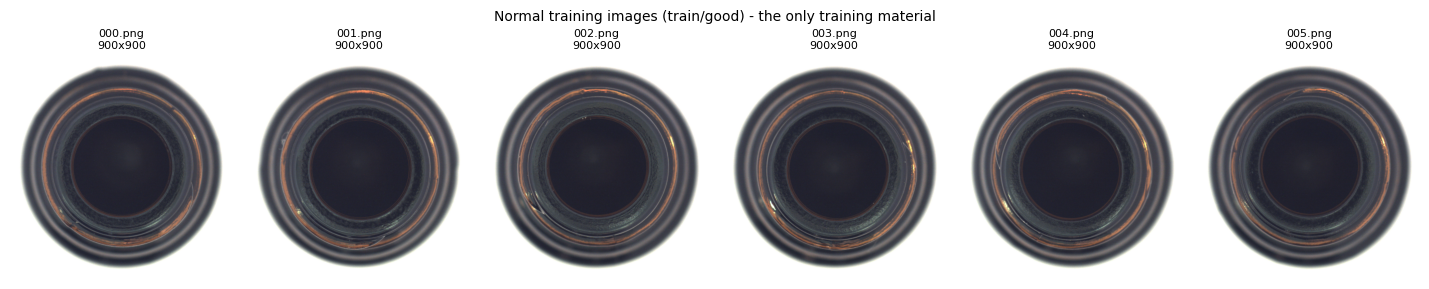

formats          : {'PNG': 292}
pixel modes      : {'RGB': 292}  (all converted to RGB by the loader)
original sizes   : {(900, 900): 292}
dtype / range    : uint8, pixels in [0, 255], 3 channels
mean RGB of shown: [136.3 135.3 139.4]
After the pipeline (Section 3): resized to the configured image_size (default 256x256), converted to float32 in [0, 1], channels-first (CHW).


In [20]:
# Visual + numeric sample of normal training images.
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

sample_paths = report.train_good[:6]
fig, axes = plt.subplots(1, len(sample_paths), figsize=(2.4 * len(sample_paths), 3.0), squeeze=False)

channel_means = []
for ax, path in zip(axes[0], sample_paths):
    with Image.open(path) as img:
        image = img.convert("RGB")
        array = np.asarray(image)
    ax.imshow(image)
    ax.set_title(f"{path.name}\n{array.shape[1]}x{array.shape[0]}", fontsize=8)
    ax.axis("off")
    channel_means.append(array.reshape(-1, 3).mean(axis=0))

plt.suptitle("Normal training images (train/good) - the only training material", fontsize=10)
plt.tight_layout()
plt.show()

sizes = dict(report.sizes)
modes = dict(report.modes)
print(f"formats          : {dict(report.formats)}")
print(f"pixel modes      : {modes}  (all converted to RGB by the loader)")
print(f"original sizes   : {sizes}")
print(f"dtype / range    : uint8, pixels in [0, 255], 3 channels")
print(f"mean RGB of shown: {np.mean(channel_means, axis=0).round(1)}")
print(
    "After the pipeline (Section 3): resized to the configured image_size "
    "(default 256x256), converted to float32 in [0, 1], channels-first (CHW)."
)


## Section 3 - Data preprocessing

The loader (`src/data/dataset.py`) does four things, in order:

1. **Open + convert** - every file is decoded with PIL and converted to RGB, so grayscale or RGBA files cannot change the channel count mid-epoch. A file that fails to decode raises an error naming the path; nothing is skipped silently.
2. **Resize** - MVTec AD `bottle` images are 900x900. We resize to a configurable square resolution (default **256x256**). The trade-off: larger keeps more defect detail (fine scratches survive) but costs GPU memory and speed roughly quadratically; 256x256 keeps a T4 comfortable at batch 16 while retaining object-scale structure. Objects stay centred, so plain resize (no crop) keeps the whole bottle in frame.
3. **ToTensor** - HWC uint8 `[0, 255]` becomes CHW float32 `[0, 1]`.
4. **No mean/std normalisation** - the `[0, 1]` range is kept as-is on purpose: the decoder ends in a **sigmoid** (outputs also `[0, 1]`), so input and reconstruction share one range and pixel-wise error maps stay directly interpretable.

**Split rule:** the validation set is carved out of `train/good` only, with a seeded shuffle (`split_train_val`). The official `test/` split stays untouched for the evaluation notebook. Training shuffling is seeded too (`generator` on the DataLoader), so two runs with the same config see the same batches.


In [21]:
# Load the experiment configuration (defaults <- YAML <- notebook overrides).
CONFIG_PATH = REPO_ROOT / "configs" / "default.yaml"

# Uncomment lines to override anything for a quick smoke run; the file stays the
# single source of truth for full experiments.
OVERRIDES = {
    # "experiment_name": "baseline_bottle_smoke",
    # "train": {"epochs": 3},
    # "data": {"image_size": 128, "batch_size": 8},
}

cfg = load_experiment_config(CONFIG_PATH, overrides=OVERRIDES or None)
print(f"experiment     : {cfg.experiment_name}")
print(f"category       : {cfg.category}")
print(f"seed           : {cfg.seed}")
print(f"image_size     : {cfg.data.image_size}  (divisible by 2**{cfg.model.num_downsamples} = {cfg.model.downsample_factor})")
print(f"batch_size     : {cfg.data.batch_size}   val_fraction: {cfg.data.val_fraction}")
print(f"model          : base={cfg.model.base_channels} mults={list(cfg.model.channel_mults)} "
      f"latent={cfg.model.latent_channels} convs/stage={cfg.model.num_convs_per_stage}")
print(f"optimizer      : {cfg.train.optimizer}  lr={cfg.train.lr}  epochs={cfg.train.epochs}  grad_clip={cfg.train.grad_clip}")


experiment     : baseline_bottle
category       : bottle
seed           : 42
image_size     : 256  (divisible by 2**5 = 32)
batch_size     : 16   val_fraction: 0.1
model          : base=32 mults=[1, 2, 4, 8, 8] latent=256 convs/stage=2
optimizer      : adam  lr=0.001  epochs=30  grad_clip=1.0


In [22]:
# Build train/validation dataloaders from train/good ONLY, then inspect one batch.
import sys

num_workers = cfg.data.num_workers
if sys.platform.startswith("win") and num_workers > 0:
    print("Windows detected: forcing num_workers=0 (notebook + spawned workers clash).")
    num_workers = 0

pin_memory = DEVICE.type == "cuda"
train_loader, val_loader, split_info = create_dataloaders(
    DATASET_ROOT,
    category=cfg.category,
    image_size=cfg.data.image_size,
    batch_size=cfg.data.batch_size,
    val_fraction=cfg.data.val_fraction,
    seed=cfg.seed,
    num_workers=num_workers,
    pin_memory=pin_memory,
)

batches_per_epoch = len(train_loader)
print(f"train images   : {split_info['n_train']}  ({batches_per_epoch} batches/epoch, drop_last=True)")
if val_loader is not None:
    print(f"val images     : {split_info['n_val']}  ({len(val_loader)} batches, drop_last=False)")
else:
    print("val images     : 0 (val_fraction=0.0) - model selection will use train loss")

# The split must contain ONLY normal training images - prove it from the paths.
def _is_train_good(path_str: str) -> bool:
    return "/train/good/" in Path(path_str).as_posix()

assert split_info["n_train"] + split_info["n_val"] == split_info["n_all_train_good"]
assert all(_is_train_good(p) for p in split_info["train_paths"]), "Non train/good path leaked into training!"
assert all(_is_train_good(p) for p in split_info["val_paths"]), "Non train/good path leaked into validation!"
print("split audit    : every train/val path lives under train/good  -> PASS")

batch = next(iter(train_loader))
images, batch_paths = batch["image"], batch["path"]
print(f"batch shape    : {tuple(images.shape)}  dtype {images.dtype}  device will be {DEVICE}")
print(f"batch range    : [{float(images.min()):.3f}, {float(images.max()):.3f}]  (expected [0, 1])")
print(f"example path   : {batch_paths[0]}")

assert images.ndim == 4 and images.shape[1] == cfg.model.in_channels
assert images.dtype == torch.float32
assert float(images.min()) >= 0.0 and float(images.max()) <= 1.0
LOADERS_OK = True


train images   : 188  (11 batches/epoch, drop_last=True)
val images     : 21  (2 batches, drop_last=False)
split audit    : every train/val path lives under train/good  -> PASS
batch shape    : (16, 3, 256, 256)  dtype torch.float32  device will be cuda
batch range    : [0.114, 1.000]  (expected [0, 1])
example path   : /content/datasets/mvtec/kaggle/mvtec_anomaly_detection/bottle/train/good/010.png


## Section 4 - CNN encoder

The encoder (`src/models/encoder.py`) compresses an image into a latent code using only ordinary, randomly initialised layers:

- **ConvBlock** = two `Conv2d(3x3, padding=1) -> BatchNorm2d -> ReLU` stacks. Padding keeps H and W unchanged; BatchNorm stabilises the activation scales of a from-scratch network, which is what makes short Colab runs trainable at all.
- **MaxPool2d(2)** after each stage halves H and W.
- A final **1x1 conv** projects the last stage to `latent_channels` without changing the spatial size.

With the defaults (`base_channels=32`, `channel_mults=[1,2,4,8,8]`, 256x256 input) the tensor evolves as follows (printed for real below):

```text
input                     3ch 256x256
stage 0 ConvBlock   3-> 32  32ch 256x256  -> pool ->  32ch 128x128
stage 1 ConvBlock  32-> 64  64ch 128x128  -> pool ->  64ch  64x64
stage 2 ConvBlock  64->128 128ch  64x64   -> pool -> 128ch  32x32
stage 3 ConvBlock 128->256 256ch  32x32   -> pool -> 256ch  16x16
stage 4 ConvBlock 256->256 256ch  16x16   -> pool -> 256ch   8x8
bottleneck 1x1             256ch   8x8    <- latent code z
```

The latent keeps a small **spatial** layout (8x8) instead of a flat vector: that is what lets the decoder upsample symmetrically. Compression is 12x in element count (196,608 input floats -> 16,384 latent floats per image), and the decoder only sees `z` - **there are no skip connections**, so the model cannot simply copy the input through the network (which would defeat the anomaly-detection hypothesis).


In [23]:
# Build the encoder and print the real stage table + a dummy forward check.
from src.models import Encoder

encoder = Encoder(
    in_channels=cfg.model.in_channels,
    base_channels=cfg.model.base_channels,
    channel_mults=cfg.model.channel_mults,
    latent_channels=cfg.model.latent_channels,
    num_convs_per_stage=cfg.model.num_convs_per_stage,
).to(DEVICE)

size = cfg.data.image_size
print(f"Encoder stage table (input 1x{cfg.model.in_channels}x{size}x{size}):")
spatial = size
channels_in = cfg.model.in_channels
print(f"  {'input':24s} {channels_in:4d}ch {spatial:4d}x{spatial}")
for index, mult in enumerate(cfg.model.channel_mults):
    channels_out = cfg.model.base_channels * mult
    print(f"  encoder.stages.{index} ConvBlock {channels_in:3d}->{channels_out:3d} {channels_out:4d}ch {spatial:4d}x{spatial}")
    spatial //= 2
    print(f"  {'  -> MaxPool2d(2)':24s} {channels_out:4d}ch {spatial:4d}x{spatial}")
    channels_in = channels_out
print(f"  {'  -> bottleneck 1x1':24s} {cfg.model.latent_channels:4d}ch {spatial:4d}x{spatial}   <- latent z")

encoder.eval()
with torch.no_grad():
    z = encoder(torch.zeros(1, cfg.model.in_channels, size, size, device=DEVICE))
expected_spatial = size // (2 ** encoder.num_downsamples)
expected_shape = (1, cfg.model.latent_channels, expected_spatial, expected_spatial)
print(f"\ndummy forward : {tuple(z.shape)}  (expected {expected_shape})")
assert tuple(z.shape) == expected_shape, f"Encoder latent shape {tuple(z.shape)} != {expected_shape}"
print("encoder check : PASS")


Encoder stage table (input 1x3x256x256):
  input                       3ch  256x256
  encoder.stages.0 ConvBlock   3-> 32   32ch  256x256
    -> MaxPool2d(2)          32ch  128x128
  encoder.stages.1 ConvBlock  32-> 64   64ch  128x128
    -> MaxPool2d(2)          64ch   64x64
  encoder.stages.2 ConvBlock  64->128  128ch   64x64
    -> MaxPool2d(2)         128ch   32x32
  encoder.stages.3 ConvBlock 128->256  256ch   32x32
    -> MaxPool2d(2)         256ch   16x16
  encoder.stages.4 ConvBlock 256->256  256ch   16x16
    -> MaxPool2d(2)         256ch    8x8
    -> bottleneck 1x1       256ch    8x8   <- latent z

dummy forward : (1, 256, 8, 8)  (expected (1, 256, 8, 8))
encoder check : PASS


## Section 5 - Decoder

The decoder (`src/models/decoder.py`) mirrors the encoder in reverse:

- **Upsample(scale_factor=2, mode="nearest")** doubles H and W, then a **ConvBlock** mixes and refines channels. Nearest-neighbour + normal convolution is used instead of `ConvTranspose2d` because transposed convolutions can learn uneven overlap and leave a checkerboard pattern on the images.
- Channel counts follow the encoder's `channel_mults` in reverse, so the widest stages sit at the smallest resolutions (where spatial detail is cheapest to process).
- The final `Conv2d(3x3)` produces `in_channels` output maps, and a **sigmoid** squashes every value into `[0, 1]` - the same range the inputs were normalised to in Section 3. Input range and output activation must match, otherwise MSE would compare incompatible scales.

**Why the output will not equal the input:** the decoder only ever sees the latent code `z`, a 12x compression of the image. MSE training rewards "a plausible normal bottle", not a bit-exact copy; low-frequency structure (shape, colour, lighting) is cheap to reproduce, fine texture is not. Watching *where* the reconstruction differs is exactly what Section 10 visualises - and, later, what anomaly scoring will build on.


In [24]:
# Build the decoder, print the mirrored stage table, and check the output contract.
from src.models import Decoder

decoder = Decoder(
    out_channels=cfg.model.in_channels,
    base_channels=cfg.model.base_channels,
    channel_mults=cfg.model.channel_mults,
    latent_channels=cfg.model.latent_channels,
    num_convs_per_stage=cfg.model.num_convs_per_stage,
).to(DEVICE)

spatial = size // cfg.model.downsample_factor
channels_in = cfg.model.latent_channels
print(f"Decoder stage table (latent 1x{cfg.model.latent_channels}x{spatial}x{spatial}):")
for index, mult in enumerate(reversed(cfg.model.channel_mults)):
    channels_out = cfg.model.base_channels * mult
    spatial *= 2
    print(f"  decoder.stages.{index} Upsample x2 + ConvBlock {channels_in:3d}->{channels_out:3d} {channels_out:4d}ch {spatial:4d}x{spatial}")
    channels_in = channels_out
print(f"  {'head Conv2d 3x3 + sigmoid':40s} {cfg.model.in_channels:4d}ch {spatial:4d}x{spatial}   <- reconstruction x_hat")

decoder.eval()
with torch.no_grad():
    z0 = torch.zeros(1, cfg.model.latent_channels, size // cfg.model.downsample_factor, size // cfg.model.downsample_factor, device=DEVICE)
    x_hat = decoder(z0)
expected = (1, cfg.model.in_channels, size, size)
print(f"\ndummy forward : {tuple(x_hat.shape)}  (expected {expected})")
print(f"output range  : [{float(x_hat.min()):.3f}, {float(x_hat.max()):.3f}]  (sigmoid -> [0, 1])")
assert tuple(x_hat.shape) == expected, f"Decoder output shape {tuple(x_hat.shape)} != {expected}"
assert float(x_hat.min()) >= 0.0 and float(x_hat.max()) <= 1.0
print("decoder check : PASS")


Decoder stage table (latent 1x256x8x8):
  decoder.stages.0 Upsample x2 + ConvBlock 256->256  256ch   16x16
  decoder.stages.1 Upsample x2 + ConvBlock 256->256  256ch   32x32
  decoder.stages.2 Upsample x2 + ConvBlock 256->128  128ch   64x64
  decoder.stages.3 Upsample x2 + ConvBlock 128-> 64   64ch  128x128
  decoder.stages.4 Upsample x2 + ConvBlock  64-> 32   32ch  256x256
  head Conv2d 3x3 + sigmoid                   3ch  256x256   <- reconstruction x_hat

dummy forward : (1, 3, 256, 256)  (expected (1, 3, 256, 256))
output range  : [0.497, 0.509]  (sigmoid -> [0, 1])
decoder check : PASS


## Section 6 - Assemble the autoencoder

`Autoencoder` (`src/models/autoencoder.py`) glues encoder and decoder together and exposes `encode` / `decode` separately (later anomaly scoring will want the latent without rebuilding the model). Before any training, the cell below verifies the contracts that most commonly break in practice:

- output shape equals input shape, for several batch sizes,
- outputs are finite (no NaN/Inf from a bad initialisation),
- gradients reach **every** trainable parameter after one backward pass,
- the whole model actually lives on the selected device.


In [25]:
# Assemble, count parameters, and print a per-stage shape report.
from src.models import count_parameters_by_part, count_trainable_parameters, tensor_shape_report

model = Autoencoder.from_config(cfg.model).to(DEVICE)
total_params = count_trainable_parameters(model)
parts = count_parameters_by_part(model)

latent_spatial = size // cfg.model.downsample_factor
latent_elements = cfg.model.latent_channels * latent_spatial * latent_spatial
input_elements = cfg.model.in_channels * size * size

print(f"trainable parameters : {total_params:,}")
print(f"  encoder            : {parts['encoder']:,}")
print(f"  decoder            : {parts['decoder']:,}")
print(f"latent per image     : {cfg.model.latent_channels}x{latent_spatial}x{latent_spatial} = {latent_elements:,} floats")
print(f"input per image      : {cfg.model.in_channels}x{size}x{size} = {input_elements:,} floats")
print(f"compression ratio    : {input_elements / latent_elements:.1f}x")
assert total_params > 0

print("\nTensor shape report (dummy forward, batch 1):")
for line in tensor_shape_report(model, input_shape=(1, cfg.model.in_channels, size, size), device=DEVICE):
    print("  " + line)


trainable parameters : 5,363,395
  encoder            : 2,419,680
  decoder            : 2,943,715
latent per image     : 256x8x8 = 16,384 floats
input per image      : 3x256x256 = 196,608 floats
compression ratio    : 12.0x

Tensor shape report (dummy forward, batch 1):
  encoder.stages.0       output (1, 32, 256, 256)      module params    10,208
  encoder.pool           output (1, 32, 128, 128)      module params         0
  encoder.stages.1       output (1, 64, 128, 128)      module params    55,552
  encoder.pool           output (1, 64, 64, 64)        module params         0
  encoder.stages.2       output (1, 128, 64, 64)       module params   221,696
  encoder.pool           output (1, 128, 32, 32)       module params         0
  encoder.stages.3       output (1, 256, 32, 32)       module params   885,760
  encoder.pool           output (1, 256, 16, 16)       module params         0
  encoder.stages.4       output (1, 256, 16, 16)       module params 1,180,672
  encoder.pool   

In [27]:
# Contract checks: shapes, finiteness, gradient flow, device placement.
model.eval()
with torch.no_grad():
    for batch_size in (1, 2, cfg.data.batch_size):
        x = torch.randn(batch_size, cfg.model.in_channels, size, size, device=DEVICE)
        out = model(x)
        assert out.shape == x.shape, f"batch {batch_size}: {tuple(out.shape)} != {tuple(x.shape)}"
        assert bool(torch.isfinite(out).all()), f"batch {batch_size}: non-finite output"
        assert float(out.min()) >= 0.0 and float(out.max()) <= 1.0
        print(f"batch {batch_size:2d}: {tuple(x.shape)} -> {tuple(out.shape)}  range [{float(out.min()):.3f}, {float(out.max()):.3f}]  PASS")

# Gradient flow: one backward on a real batch; every trainable param must get a grad.
model.train()
batch = next(iter(train_loader))
x = batch["image"].to(DEVICE)
model.zero_grad(set_to_none=True)
probe_loss = (model(x) - x).pow(2).mean()  # same objective as Section 7's criterion
probe_loss.backward()

missing_grads = [
    name for name, p in model.named_parameters() if p.requires_grad and p.grad is None
]
empty_grads = [
    name
    for name, p in model.named_parameters()
    if p.requires_grad and p.grad is not None and float(p.grad.abs().sum()) == 0.0
]
print(f"\nprobe loss on a random-init batch : {float(probe_loss):.4f} (large is expected before training)")
print(f"parameters with gradients          : {total_params - len(missing_grads)}/{total_params}")
if empty_grads:
    print(f"parameters with exactly-zero grad : {len(empty_grads)} {empty_grads[:5]}")
assert not missing_grads, f"These parameters received no gradient: {missing_grads}"

model.zero_grad(set_to_none=True)
# torch.device('cuda') means "current CUDA device" (index=None), while .to(DEVICE)
# materialises parameters on the concrete device cuda:0 - so `cuda:0 == cuda` is
# False in PyTorch. Compare types and treat a None index as "any index" (on CPU
# both indexes are None, so this stays correct there too).
model_device = next(model.parameters()).device
device_match = model_device.type == DEVICE.type and (
    model_device.index is None or DEVICE.index is None or model_device.index == DEVICE.index
)
print(f"model on {model_device} (selected {DEVICE})  -> {'PASS' if device_match else 'FAIL'}")
assert device_match, f"model parameters live on {model_device}, expected {DEVICE}"
ARCH_OK = True
GRAD_OK = True


batch  1: (1, 3, 256, 256) -> (1, 3, 256, 256)  range [0.489, 0.511]  PASS
batch  2: (2, 3, 256, 256) -> (2, 3, 256, 256)  range [0.489, 0.511]  PASS
batch 16: (16, 3, 256, 256) -> (16, 3, 256, 256)  range [0.489, 0.511]  PASS

probe loss on a random-init batch : 0.1394 (large is expected before training)
parameters with gradients          : 5363395/5363395
model on cuda:0 (selected cuda)  -> PASS


## Section 7 - Reconstruction loss (MSE)

The baseline loss is mean squared error between the input image and its reconstruction:

```text
L_MSE = (1/N) * sum_{i=1..N} (x_i - x_hat_i)^2
```

- `x`     - the input batch: normal images, float32 in `[0, 1]`, shape `(B, 3, H, W)`.
- `x_hat` - the model's reconstruction of that same batch, same shape and range.
- `L_MSE` - one scalar: the average squared pixel difference over the whole batch. Smaller means "the model reproduces normal images more faithfully".

`src/losses/reconstruction.py` also provides `per_image_mse` (one value per image, for statistics) and `absolute_error_map` (a per-pixel `|x_hat - x|` map, for Section 10's visuals). Edge-aware or multi-scale terms are deliberately absent - they belong to later phases and must earn their place against this baseline.


In [28]:
# Criterion + consistency checks on a real batch.
from src.losses import absolute_error_map, per_image_mse

criterion = ReconstructionLoss(reduction="mean")
print(f"criterion : {criterion}")

batch = next(iter(train_loader))
x = batch["image"].to(DEVICE)
model.eval()
with torch.no_grad():
    recon = model(x)
    loss = criterion(recon, x)

assert loss.ndim == 0, "criterion must return a scalar"
assert bool(torch.isfinite(loss)), "loss is not finite"
per_image = per_image_mse(recon, x)
assert tuple(per_image.shape) == (x.shape[0],)
assert abs(float(per_image.mean()) - float(loss)) < 1e-5, "per-image mean != batch loss"
error_map = absolute_error_map(recon, x)
assert tuple(error_map.shape) == (x.shape[0], size, size)

print(f"MSE on this batch          : {float(loss):.6f}")
print(f"per-image MSE (first 4)    : {[round(v, 6) for v in per_image[:4].tolist()]}")
print(f"input range                : [{float(x.min()):.3f}, {float(x.max()):.3f}]")
print(f"reconstruction range       : [{float(recon.min()):.3f}, {float(recon.max()):.3f}]  <- must share the input range")
print(f"error map shape (B,H,W)    : {tuple(error_map.shape)}")
LOSS_OK = True


criterion : ReconstructionLoss(reduction='mean')
MSE on this batch          : 0.131126
per-image MSE (first 4)    : [0.130652, 0.131881, 0.130437, 0.132356]
input range                : [0.114, 1.000]
reconstruction range       : [0.488, 0.513]  <- must share the input range
error map shape (B,H,W)    : (16, 256, 256)


## Section 8 - Training implementation

The loop lives in `src/training/trainer.py` so notebooks stay thin. What `Trainer` guarantees:

| Concern | Implementation |
|---|---|
| Optimizer | Adam or AdamW via `build_optimizer` (config key `train.optimizer`) |
| Device | model + batches moved to GPU with `non_blocking=True` |
| Epoch loss | batch means weighted by batch size (last short val batch cannot skew it) |
| Non-finite loss | `FloatingPointError` with epoch/batch context - the run stops instead of writing NaN checkpoints |
| Validation | optional, normal held-out images only; also used to pick `best.pt` |
| Timing | per-epoch and total wall-clock seconds |
| Checkpoints | `last.pt` every epoch; `best.pt` on improvement; both store model/optimizer/RNG state and the config |
| Resume | `fit(..., resume_from=...)` restores states and continues at the next epoch |
| Artifacts | `history.json` after every epoch; `config.yaml` + `metadata.json` written by the notebook |

Only normal `train/good` images reach the loop: the loaders were built from that folder in Section 3, and the validation loader holds only held-out normal images. Nothing here can leak defective test data into training or model selection.


In [29]:
# Optimizer + trainer wiring (training itself runs in Section 9).
from src.training import Trainer, build_optimizer

optimizer = build_optimizer(model, cfg.train.optimizer, cfg.train.lr, cfg.train.weight_decay)
print(f"optimizer : {type(optimizer).__name__}")
print(f"lr        : {cfg.train.lr}")
print(f"weight_decay: {cfg.train.weight_decay}")
print(f"grad_clip : {cfg.train.grad_clip}  (0.0 would disable clipping)")
print(f"device    : {DEVICE}")


optimizer : Adam
lr        : 0.001
weight_decay: 0.0
grad_clip : 1.0  (0.0 would disable clipping)
device    : cuda


## Section 9 - Configure and train

1. Create a run directory under `outputs/runs/<experiment_name>/` (git-ignored).
2. Persist the resolved config and the dataset split (auditable later).
3. Train with the settings from `configs/default.yaml` - conservative defaults that fit a Colab T4: 256x256, batch 16, Adam `lr=1e-3`, 30 epochs (~13 batches/epoch on `bottle`).
4. Plot the recorded losses, then show held-out normal images next to their reconstructions.

To change resolution, batch size, learning rate or epochs, edit `configs/default.yaml` (or uncomment an override in the config cell) and re-run from that cell. To resume an interrupted run, set `RESUME_FROM` below to the `last.pt` path.


In [30]:
# Run directory + persisted config/split + resume switch.
import json

RUN_DIR = paths.outputs / "runs" / cfg.experiment_name
RUN_DIR.mkdir(parents=True, exist_ok=True)
save_experiment_config(cfg, RUN_DIR / "config.yaml")
(RUN_DIR / "split_info.json").write_text(json.dumps(split_info, indent=2), encoding="utf-8")

RESUME_FROM = None  # e.g. RUN_DIR / "checkpoints" / "last.pt" to continue an interrupted run

print(f"run directory : {RUN_DIR}")
print(f"checkpoints   : {RUN_DIR / 'checkpoints'}")
print(f"config saved  : {RUN_DIR / 'config.yaml'}")
print(f"split saved   : {RUN_DIR / 'split_info.json'}")
print(f"RESUME_FROM   : {RESUME_FROM}")


run directory : /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle
checkpoints   : /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/checkpoints
config saved  : /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/config.yaml
split saved   : /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/split_info.json
RESUME_FROM   : None


In [31]:
# Train. Every epoch prints its real losses; nothing here is pre-filled.
trainer = Trainer(
    model,
    criterion,
    optimizer,
    DEVICE,
    run_dir=RUN_DIR,
    grad_clip=cfg.train.grad_clip,
    config=cfg.to_dict(),
)

result = trainer.fit(
    train_loader,
    val_loader,
    epochs=cfg.train.epochs,
    resume_from=RESUME_FROM,
)

assert len(result.records) >= 1, "Training produced no epoch records"
losses_finite = all(
    r.train_loss == r.train_loss and (r.val_loss is None or r.val_loss == r.val_loss)
    for r in result.records
)
assert losses_finite, "Training recorded a non-finite loss"

first, last = result.records[0], result.records[-1]
print(f"\nepochs recorded        : {len(result.records)} (last: epoch {last.epoch})")
print(f"train loss first/last  : {first.train_loss:.6f} -> {last.train_loss:.6f}")
if last.val_loss is not None:
    print(f"val loss first/last    : {first.val_loss:.6f} -> {last.val_loss:.6f}")
print(f"total training time    : {result.total_seconds / 60:.1f} min")
print(f"best metric            : {result.best_metric:.6f}")
print(f"last checkpoint        : {result.checkpoint_paths['last.pt']}")
print(f"best checkpoint        : {result.checkpoint_paths['best.pt']}")
TRAIN_OK = True


epoch   1/30  train_loss 0.068142  val_loss 0.256651     6.3s  (val_loss 0.256651 *)
epoch   2/30  train_loss 0.007877  val_loss 0.093526     6.2s  (val_loss 0.093526 *)
epoch   3/30  train_loss 0.004155  val_loss 0.025686     6.0s  (val_loss 0.025686 *)
epoch   4/30  train_loss 0.003023  val_loss 0.010265     5.9s  (val_loss 0.010265 *)
epoch   5/30  train_loss 0.002758  val_loss 0.005487     6.1s  (val_loss 0.005487 *)
epoch   6/30  train_loss 0.002596  val_loss 0.002818     6.1s  (val_loss 0.002818 *)
epoch   7/30  train_loss 0.002644  val_loss 0.002524     6.0s  (val_loss 0.002524 *)
epoch   8/30  train_loss 0.002785  val_loss 0.003179     6.1s  (val_loss 0.003179)
epoch   9/30  train_loss 0.002615  val_loss 0.003333     6.1s  (val_loss 0.003333)
epoch  10/30  train_loss 0.002454  val_loss 0.002497     6.1s  (val_loss 0.002497 *)
epoch  11/30  train_loss 0.002491  val_loss 0.003293     6.3s  (val_loss 0.003293)
epoch  12/30  train_loss 0.002545  val_loss 0.002526     6.0s  (val_los

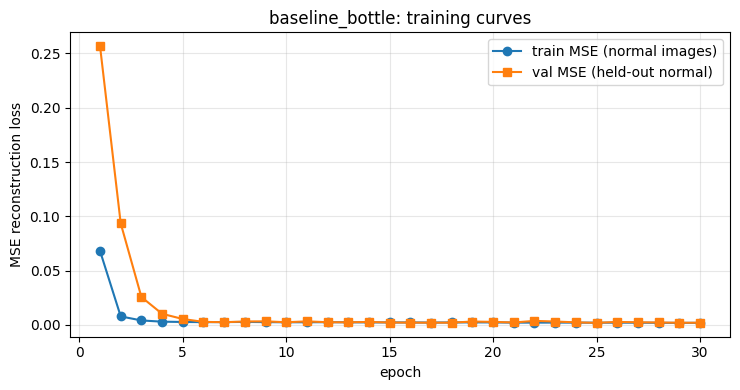

saved: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures/loss_curves.png


In [32]:
# Loss curves from the recorded history (no re-computation).
import matplotlib.pyplot as plt

epochs = [r.epoch for r in result.records]
train_losses = [r.train_loss for r in result.records]
val_points = [(r.epoch, r.val_loss) for r in result.records if r.val_loss is not None]

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(epochs, train_losses, "o-", label="train MSE (normal images)")
if val_points:
    ax.plot([e for e, _ in val_points], [v for _, v in val_points], "s-", label="val MSE (held-out normal)")
ax.set_xlabel("epoch")
ax.set_ylabel("MSE reconstruction loss")
ax.set_title(f"{cfg.experiment_name}: training curves")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
figures_dir = RUN_DIR / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
loss_fig_path = figures_dir / "loss_curves.png"
fig.savefig(loss_fig_path, dpi=150)
plt.show()
print(f"saved: {loss_fig_path}")


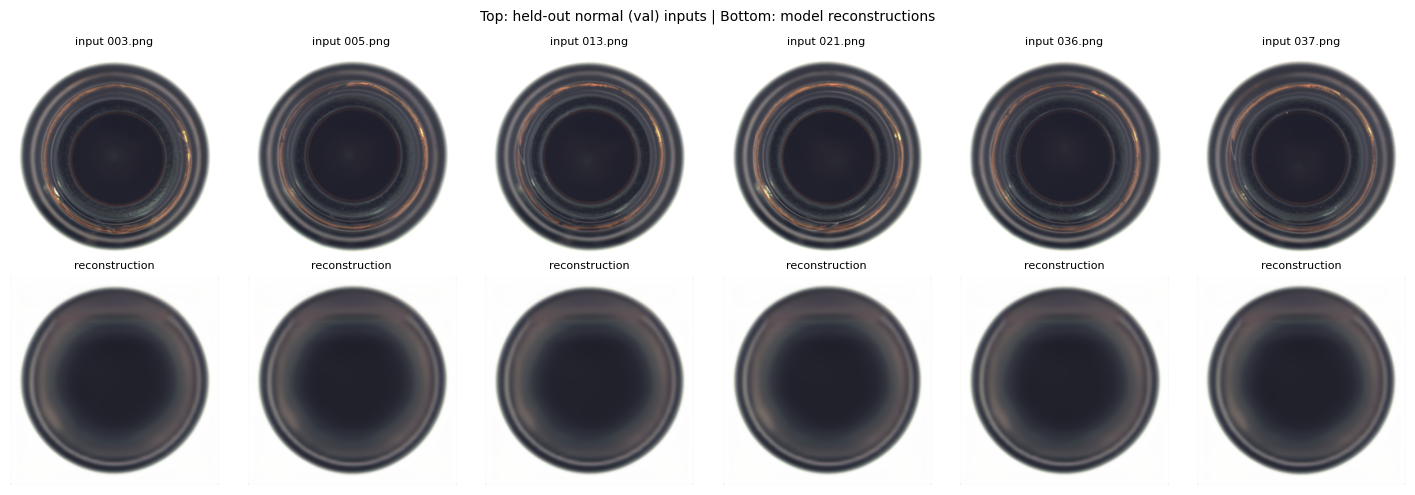

In [33]:
# Show held-out normal inputs next to their reconstructions.
model.eval()
show_loader = val_loader if val_loader is not None else train_loader
split_name = "held-out normal (val)" if val_loader is not None else "train/good"
batch = next(iter(show_loader))
n_show = min(6, batch["image"].shape[0])
images = batch["image"][:n_show].to(DEVICE)
names = [Path(p).name for p in batch["path"][:n_show]]

with torch.no_grad():
    recons = model(images)

fig, axes = plt.subplots(2, n_show, figsize=(2.4 * n_show, 5.0), squeeze=False)
for index in range(n_show):
    axes[0][index].imshow(images[index].cpu().permute(1, 2, 0).clamp(0, 1))
    axes[0][index].set_title(f"input {names[index]}", fontsize=8)
    axes[1][index].imshow(recons[index].cpu().permute(1, 2, 0).clamp(0, 1))
    axes[1][index].set_title("reconstruction", fontsize=8)
    for row in (0, 1):
        axes[row][index].axis("off")

plt.suptitle(f"Top: {split_name} inputs | Bottom: model reconstructions", fontsize=10)
plt.tight_layout()
plt.show()


## Section 10 - Reconstruction analysis

Three rows per image: the normal input, its reconstruction, and the absolute pixel-wise difference `|x_hat - x|` (averaged over RGB channels). The difference row uses one shared colour scale across the batch so panels are comparable - without that, each map would auto-scale and a mostly-perfect image would look as alarming as a bad one.

**What this shows:** where the model reproduces normal structure well (bottle edges, label, background) and where it struggles (fine texture, highlights, boundary softness). Expect a faint outline along strong edges early in training: the bottleneck cannot preserve every high-frequency detail, and MSE itself under-weights them.

**What this does NOT show:** that anomaly detection works. Every image here is *normal* - the model has never seen a defect. Good reconstruction of normal images is necessary but not sufficient. Two failure modes remain untested:

1. The model may reconstruct defects almost as well as normal structure (defects are often small and the model generalises), leaving no error contrast.
2. The model may simply blur hard regions, producing high error everywhere - useless for localisation.

Only the evaluation notebook (defective test images + ground-truth masks, AUROC/pro images) can answer whether reconstruction error separates anomalies. No anomalous image or mask is used in this notebook - not for training, not for tuning, not for choosing checkpoints.


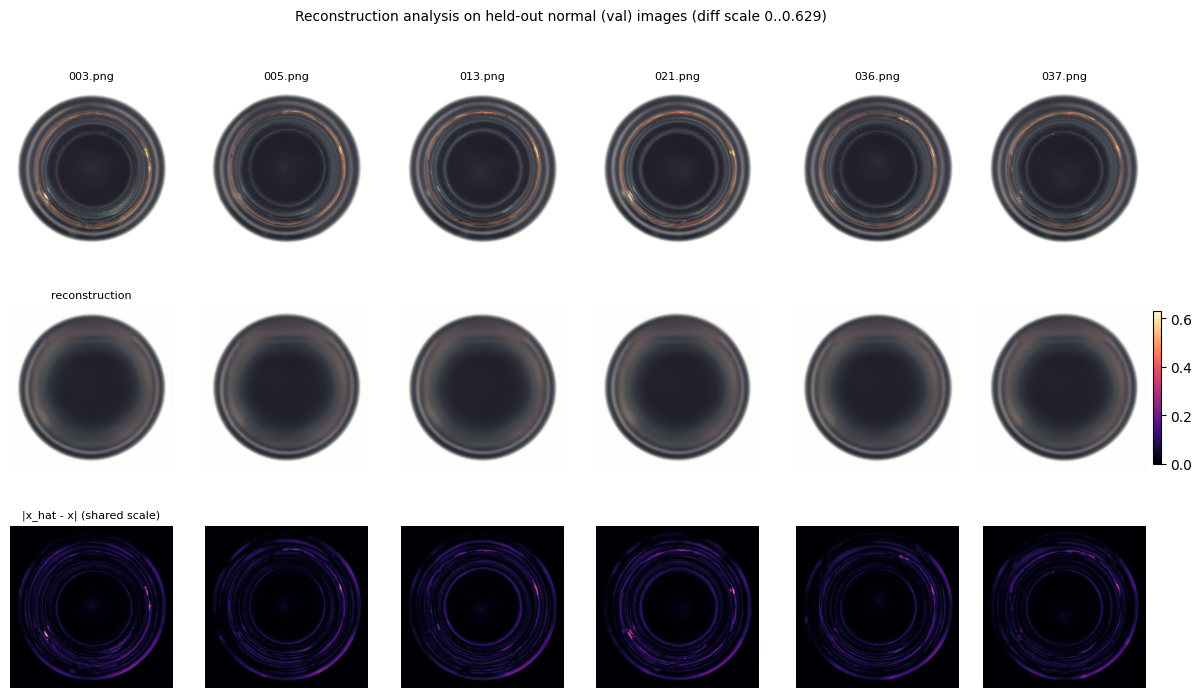

saved: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/figures/reconstruction_analysis.png
image           per-image MSE  max |diff|
003.png              0.002075    0.628766
005.png              0.001789    0.534372
013.png              0.001979    0.450959
021.png              0.002285    0.550005
036.png              0.001689    0.485297
037.png              0.001636    0.453451


In [34]:
# Original | reconstruction | absolute difference with a shared colour scale.
from src.losses import absolute_error_map, per_image_mse

model.eval()
batch = next(iter(show_loader))
n_show = min(6, batch["image"].shape[0])
images = batch["image"][:n_show].to(DEVICE)
names = [Path(p).name for p in batch["path"][:n_show]]

with torch.no_grad():
    recons = model(images)
    err = absolute_error_map(recons, images)          # (B, H, W), channel-averaged |x_hat - x|
    img_mse = per_image_mse(recons, images)           # (B,)

shared_vmax = max(0.05, float(err.max()))            # one scale for every panel in the row

fig = plt.figure(figsize=(2.5 * n_show, 7.8))
gs = fig.add_gridspec(3, n_show, hspace=0.35, wspace=0.05)
for index in range(n_show):
    ax_in = fig.add_subplot(gs[0, index])
    ax_in.imshow(images[index].cpu().permute(1, 2, 0).clamp(0, 1))
    ax_in.set_title(names[index], fontsize=8)
    ax_in.axis("off")

    ax_re = fig.add_subplot(gs[1, index])
    ax_re.imshow(recons[index].cpu().permute(1, 2, 0).clamp(0, 1))
    if index == 0:
        ax_re.set_title("reconstruction", fontsize=8)
    ax_re.axis("off")

    ax_er = fig.add_subplot(gs[2, index])
    im = ax_er.imshow(err[index].cpu(), cmap="magma", vmin=0.0, vmax=shared_vmax)
    if index == 0:
        ax_er.set_title("|x_hat - x| (shared scale)", fontsize=8)
    ax_er.axis("off")

fig.colorbar(im, ax=fig.axes[-n_show:], fraction=0.02, pad=0.02)
plt.suptitle(f"Reconstruction analysis on {split_name} images (diff scale 0..{shared_vmax:.3f})", fontsize=10)
plt.show()

figures_dir = RUN_DIR / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
analysis_path = figures_dir / "reconstruction_analysis.png"
fig.savefig(analysis_path, dpi=150, bbox_inches="tight")
print(f"saved: {analysis_path}")
print(f"{'image':14s} {'per-image MSE':>14s} {'max |diff|':>11s}")
for name, mse, err_map in zip(names, img_mse.tolist(), err):
    print(f"{name:14s} {mse:14.6f} {float(err_map.max()):11.6f}")


## Section 11 - Checkpoint and experiment management

Everything a later notebook (or a future you) needs to reconstruct this run is written under `outputs/runs/<experiment_name>/` - git-ignored, never committed:

- `config.yaml` - the fully resolved experiment configuration,
- `split_info.json` - exact train/val file lists (auditable split),
- `history.json` - per-epoch losses and durations,
- `checkpoints/last.pt` / `best.pt` - model + optimizer + RNG state,
- `figures/` - loss curves and the reconstruction analysis,
- `metadata.json` - dataset counts, resolution, normalisation, parameter count, seed, optimizer, losses, duration, GPU.


In [35]:
# Persist run metadata and audit what exists on disk + gitignore coverage.
from src.training import write_run_metadata

metadata_path = write_run_metadata(
    RUN_DIR,
    experiment_name=cfg.experiment_name,
    category=cfg.category,
    seed=cfg.seed,
    dataset_root=str(DATASET_ROOT),
    dataset_counts={
        "train_good_total": split_info["n_all_train_good"],
        "train_used": split_info["n_train"],
        "val_used": split_info["n_val"],
        "test_untouched": len(report.test_good) + report.n_test_defective,
    },
    image_size=cfg.data.image_size,
    normalization="ToTensor -> float32 [0, 1] CHW; decoder sigmoid output",
    model_architecture=(
        f"Autoencoder(base_channels={cfg.model.base_channels}, "
        f"channel_mults={list(cfg.model.channel_mults)}, "
        f"latent_channels={cfg.model.latent_channels}, "
        f"num_convs_per_stage={cfg.model.num_convs_per_stage})"
    ),
    trainable_parameters=total_params,
    optimizer=cfg.train.optimizer,
    lr=cfg.train.lr,
    weight_decay=cfg.train.weight_decay,
    grad_clip=cfg.train.grad_clip,
    batch_size=cfg.data.batch_size,
    epochs=cfg.train.epochs,
    train_losses=[r.train_loss for r in result.records],
    val_losses=[r.val_loss for r in result.records],
    training_seconds=result.total_seconds,
    best_metric=result.best_metric,
    device=str(DEVICE),
    gpu_name=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    torch_version=torch.__version__,
)
print(f"metadata: {metadata_path}")

print(f"\nRun directory contents ({RUN_DIR}):")
for path in sorted(RUN_DIR.rglob("*")):
    rel = path.relative_to(RUN_DIR)
    if path.is_dir():
        print(f"  {rel}/")
    else:
        print(f"  {rel}  ({path.stat().st_size / 1024:.1f} KB)")

gitignore_text = (REPO_ROOT / ".gitignore").read_text(encoding="utf-8")
required_patterns = ["outputs/", "*.pt", "*.pth", "data/", "__pycache__/"]
ARTIFACTS_OK = True
print(f"\n.gitignore coverage ({REPO_ROOT / '.gitignore'}):")
for pattern in required_patterns:
    covered = any(pattern in line or pattern.lstrip("*") in line for line in gitignore_text.splitlines())
    print(f"  {'ok  ' if covered else 'MISS'}  {pattern}")
    ARTIFACTS_OK = ARTIFACTS_OK and covered
assert ARTIFACTS_OK, ".gitignore is missing patterns - large artifacts could end up in git."


metadata: /content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle/metadata.json

Run directory contents (/content/edge-aware-anomaly-detection/outputs/runs/baseline_bottle):
  checkpoints/
  checkpoints/best.pt  (62968.1 KB)
  checkpoints/last.pt  (62968.5 KB)
  config.yaml  (0.4 KB)
  figures/
  figures/loss_curves.png  (49.9 KB)
  figures/reconstruction_analysis.png  (1020.6 KB)
  history.json  (4.5 KB)
  metadata.json  (2.6 KB)
  split_info.json  (18.2 KB)

.gitignore coverage (/content/edge-aware-anomaly-detection/.gitignore):
  ok    outputs/
  ok    *.pt
  ok    *.pth
  ok    data/
  ok    __pycache__/


## Final checklist

Every line must read PASS. A FAIL means something upstream broke - fix it before moving to the evaluation notebook. The last lines restate the split rule that the rest of the project depends on.


In [36]:
# Final checklist for notebook 03.
checks = {
    "Python >= 3.9": py_ok,
    "src importable + modules hashed": SRC_OK,
    "GPU visible (hard requirement on Colab)": (gpu_ok if in_colab else True),
    "seed applied": SEED_OK,
    "dataset root located": DATASET_OK,
    "bottle scan clean (no errors)": SCAN_OK,
    "dataloaders built from train/good only": LOADERS_OK,
    "model output shape matches input": ARCH_OK,
    "gradients reach every trainable parameter": GRAD_OK,
    "MSE loss finite and consistent": LOSS_OK,
    "training recorded epochs with finite losses": TRAIN_OK,
    "checkpoints + metadata + gitignore OK": ARTIFACTS_OK,
}

width = max(len(name) for name in checks)
all_ok = True
for name, ok in checks.items():
    ok = bool(ok)
    all_ok = all_ok and ok
    print(f"[{'PASS' if ok else 'FAIL'}] {name.ljust(width)}")

assert all_ok, "Some checks failed - fix them before the evaluation notebook."
print("\nBaseline trained and archived. Next: evaluation on the untouched test set")
print("(defective images + masks, AUROC / PRO) - never used for training or tuning.")
print("Research phases still to come: multi-scale scoring, edge-aware loss, ablations.")


[PASS] Python >= 3.9                              
[PASS] src importable + modules hashed            
[PASS] GPU visible (hard requirement on Colab)    
[PASS] seed applied                               
[PASS] dataset root located                       
[PASS] bottle scan clean (no errors)              
[PASS] dataloaders built from train/good only     
[PASS] model output shape matches input           
[PASS] gradients reach every trainable parameter  
[PASS] MSE loss finite and consistent             
[PASS] training recorded epochs with finite losses
[PASS] checkpoints + metadata + gitignore OK      

Baseline trained and archived. Next: evaluation on the untouched test set
(defective images + masks, AUROC / PRO) - never used for training or tuning.
Research phases still to come: multi-scale scoring, edge-aware loss, ablations.


## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `FileNotFoundError: Could not find the MVTec AD dataset root` | dataset not downloaded/extracted yet | run `notebooks/02_dataset_inspection.ipynb`, or set `MVTEC_ROOT` |
| `Repository root not found on this runtime` | kernel cannot see your local disk | right-click the repo folder -> **Upload to Colab**, re-run |
| "Only part of the repository was uploaded" | `src/` uploaded without `configs/` | upload the WHOLE repository folder |
| `No GPU on this Colab runtime` | server created without a GPU | `Colab: Remove Server`, provision a new one, pick a GPU |
| `CUDA out of memory` during training | batch/resolution too large for the GPU | lower `data.batch_size` (e.g. 8) or `data.image_size` (e.g. 128) in `configs/default.yaml`; re-run from the config cell |
| DataLoader hangs on a **Windows** local kernel | `num_workers > 0` + notebook spawn clash | the loaders cell already forces `num_workers=0` on Windows; keep it at 0 |
| `FloatingPointError: Non-finite loss` | learning rate too high or numerical blow-up | lower `train.lr` (e.g. `0.0005`), keep `train.grad_clip: 1.0`, re-run from the config cell |
| Edited `src/` but behaviour unchanged | runtime still holds the old upload | re-upload the repository folder; compare the sha256 printed in Section 1 |
| Loss never drops much below its starting value | model collapsed to predicting a mean (grey) image | inspect the reconstruction grid: if everything is grey, lower `train.lr` (e.g. `0.0005`) and train longer |
| Want to continue an interrupted run | runtime died mid-training | on Colab, checkpoints live in `/content` and vanish on disconnect - copy `outputs/runs/...` to Drive first; then set `RESUME_FROM` |
